In [1]:
import itertools
import numpy as np
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
import random
import torch


from contextlib import contextmanager
from torch.func import jacfwd
from model_utils import (
    generate_images_from_latents,
    get_text_embeddings,
)
from matplotlib import pyplot as plt
from PIL import Image
from typing import Optional, Union, Iterable, List, Callable, Tuple

## Hyperparameters

In [2]:
model_name = "stabilityai/stable-diffusion-2-1"
batch_size = 4
num_inference_steps = 50
guidance_scale = 7.5
SEED = 10


In [3]:
os.environ["PYTHONHASprompt_embeddingEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":16:8"  # or ":4096:8" on larger GPUs
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.cuda.manual_seed(SEED)
generator=torch.Generator(device="cuda").manual_seed(SEED)

In [4]:
from diffusers import StableDiffusionPipeline, DDIMScheduler
pipe = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5").to("cuda")
vae = pipe.vae
tokenizer = pipe.tokenizer
text_encoder = pipe.text_encoder
unet = pipe.unet
scheduler = DDIMScheduler.from_config(pipe.scheduler.config)

/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 30.80it/s]


In [5]:
def show_image(image):
    image_array = np.array(image.cpu())
    image_array = (image_array - image_array.min()) / (image_array.max() - image_array.min() + 1e-8)
    image_array = (image_array * 255).astype(np.uint8)
    image_array = np.transpose(image_array, (1, 2, 0))
    image_plot = Image.fromarray(image_array, mode="RGB")

    # Show with corrected aspect ratio
    plt.figure(figsize=(10, 2))  # Adjust figsize to better match the image shape
    plt.imshow(image_plot)
    plt.axis('off')  # Optional: hides axis for better viewing
    plt.tight_layout()
    plt.show()

In [6]:
def prepare_unet_for_pullback(unet):
    """
    Call once to keep autograd stable:
    - force fp32
    - disable xFormers/mem-efficient attention if present
    - use a plain attention processor
    """
    try:
        unet.to(dtype=torch.float32)
    except Exception:
        pass
    try:
        unet.enable_xformers_memory_efficient_attention(False)
    except Exception:
        pass
    if hasattr(unet, "config"):
        try:
            setattr(unet.config, "use_memory_efficient_attention_xformers", False)
        except Exception:
            pass
    # Processor name depends on diffusers version
    try:
        from diffusers.models.attention_processor import AttnProcessor2_0 as _Attn
    except Exception:
        try:
            from diffusers.models.attention_processor import AttnProcessor as _Attn
        except Exception:
            _Attn = None
    if _Attn is not None:
        try:
            unet.set_attn_processor(_Attn())
        except Exception:
            try:
                unet.set_default_attn_processor()
            except Exception:
                pass
        

# -------------------- feature map phi(x,t,c) --------------------

def _phi_hidden(unet, x_t, t, prompt_embedding, guidance_scale, *, layer="mid_block", scheduler=None):
    """
    Capture a hidden activation from diffusers UNet via a forward hook.
    Returns the CONDITIONAL half (for CFG) flattened to 1D.
    """
    assert scheduler is not None, "Pass the scheduler so we can call scale_model_input once."

    # CFG duplication (same as your sampling path)
    uncond, cond = prompt_embedding[0:1], prompt_embedding[1:2]
    x_in = torch.cat([x_t, x_t], dim=0)          # (2,B,4,H,W) -> here B==1 so (2,4,H,W)
    t_in = torch.cat([t, t], dim=0)              # (2,)
    h_in = torch.cat([uncond, cond], dim=0)      # (2, seq, dim)

    # scale model input exactly like in your roll loop
    x_in = scheduler.scale_model_input(x_in, t)  # pass scalar timestep (broadcasts across batch)

    # pick target module
    if layer == "mid_block":
        target = unet.mid_block
    else:
        # example: ("down_blocks", -1, "resnets", -1)
        mod = unet
        for key in layer:
            mod = mod[key] if isinstance(key, int) else getattr(mod, key)
        target = mod

    captured = {}

    def _hook(_m, _inp, out):
        captured["feat"] = out

    handle = target.register_forward_hook(_hook)
    try:
        # normal UNet forward; hook grabs the chosen layer activation
        _ = unet(x_in, t_in, encoder_hidden_states=h_in)
        feats = captured.get("feat", None)
        if feats is None:
            raise RuntimeError("Hidden feature was not captured; check `layer` choice.")

        # take CONDITIONAL half (batch doubled for CFG)
        if feats.dim() >= 1 and feats.size(0) >= 2:
            feats = feats[feats.size(0)//2:]

        return feats.reshape(-1)
    finally:
        handle.remove()

# def _phi_eps(unet, x_t: torch.Tensor, t: torch.Tensor, prompt_embedding: torch.Tensor, guidance_scale: float) -> torch.Tensor:
#     """
#     Epsilon prediction as feature map (flattened).
#     Supports CFG when prompt_embedding has B=2 (uncond/cond).
#     """
#     t = t.to(x_t.device)
#     B = prompt_embedding.shape[0]
#     if B == 2:
#         uncond, cond = prompt_embedding[0:1], prompt_embedding[1:2]
#         x_in = torch.cat([x_t, x_t], dim=0)
#         t_in = torch.cat([t, t], dim=0)
#         h_in = torch.cat([uncond, cond], dim=0)
#         out  = unet(x_in, t_in, encoder_hidden_states=h_in).sample
#         eps_u, eps_c = out.chunk(2, dim=0)
#         y = eps_u + guidance_scale * (eps_c - eps_u)  
#     else:
#         y = unet(x_t, t, encoder_hidden_states=prompt_embedding).sample
#     return y.reshape(-1)

# -------------------- power iteration core --------------------

# -------------------- J_x FD-JVP + VJP --------------------

# def svd_pullback_on_x_fd(
#     unet, scheduler, *,
#     x_t,                        # (1,4,H,W) torch/numpy
#     t_index: int,
#     prompt_embedding,           # (B,seq,dim) torch/numpy
#     guidance_scale: float = 7.5,
#     select: int | list[int] | slice = 0,
#     alpha: float = 2.0,
#     k: int = 8,
#     iters: int = 20,
#     num_inference_steps: int = 50,
#     device: str = "cuda",
#     fd_eps: float = 1e-3,
#     seed: int | None = None,    # <-- NEW
# ):
#     xT = _to_torch(x_t, device).detach()
#     prompt_embedding = _to_torch(prompt_embedding, device).detach()
#     assert xT.ndim == 4 and xT.shape[0] == 1, "x_t must be (1,4,H,W)"

#     scheduler.set_timesteps(num_inference_steps, device="cuda")
#     t = scheduler.timesteps[int(t_index)].to(device).expand(1)

#     with torch.no_grad():
#         y0 = _phi_hidden(unet, xT, t, prompt_embedding, guidance_scale)

#     def Jx_v(vx: torch.Tensor) -> torch.Tensor:
#         y1 = _phi_hidden(unet, xT + fd_eps * vx, t, prompt_embedding, guidance_scale)
#         return (y1 - y0) / fd_eps

#     def JxT_u(u: torch.Tensor) -> torch.Tensor:
#         x_req = xT.clone().requires_grad_(True)
#         dot = (_phi_hidden(unet, x_req, t, prompt_embedding, guidance_scale) * u.detach()).sum()
#         (g,) = torch.autograd.grad(dot, x_req, retain_graph=False, allow_unused=True)
#         if g is None: g = torch.zeros_like(x_req)
#         return g

#     rng = _make_rng(seed, device)   # <-- NEW
#     vecs, _ = _power_right_singulars(Jx_v, JxT_u, xT.shape, k=k, iters=iters, device=device, rng=rng)

#     idxs = _parse_select(select, len(vecs))
#     if not idxs: return _back_to(xT, x_t)

#     step = torch.zeros_like(vecs[0])
#     for i in idxs:
#         step = step + vecs[i] / (vecs[i].norm() + 1e-8)
#     step = step / len(idxs)

#     x_new = xT + alpha * step
#     return _back_to(x_new, x_t)

In [ ]:
@torch.no_grad()
def roll_to_hook(x_T, prompt_embedding, *, unet, scheduler, guidance_scale, num_steps, hook_idx, device="cuda"):
    x  = x_T.to(device).clone()
    prompt_embedding = prompt_embedding.to(device)
    scheduler.set_timesteps(num_steps)
    timesteps = scheduler.timesteps.to(device)

    for i, t in enumerate(timesteps):
        if i == hook_idx:
            return x.clone(), t, i, timesteps  # only these 4 values
        
        # Expand latents for classifier-free guidance (double batch size)
        latent_model_input = torch.cat([x] * 2)
        latent_model_input = scheduler.scale_model_input(latent_model_input, timestep=t)
        
        # Disable gradients for inference
        with torch.no_grad():
            noise_pred = unet(latent_model_input, t, encoder_hidden_states=prompt_embedding).sample

        # Apply classifier-free guidance
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # Denoising step
        x = scheduler.step(noise_pred, t, x).prev_sample
        
    # fallback if hook_idx==len-1
    return x.clone(), timesteps[-1], len(timesteps)-1, timesteps


def compute_svd_basis_at_hook(
    x_t: torch.Tensor,
    t_scalar: int,
    *,
    unet,
    scheduler,
    prompt_embedding,
    guidance_scale: float = 7.5,
    k: int = 10,
    iters: int = 20,
    fd_eps: float = 1e-3,
    device: str = "cuda",
    seed: int | None = None,
    layer="mid_block",
):
    xT = x_t.detach().to(device)
    t  = torch.tensor(t_scalar, device=device).expand(1)
    prompt_embedding = prompt_embedding.to(device)

    # --- base hidden vector: NO grad needed
    with torch.no_grad():
        y0 = _phi_hidden(
            unet, xT, t, prompt_embedding, guidance_scale,
            layer=layer, scheduler=scheduler
        )

    # --- JVP via finite-difference: NO grad needed
    def Jx_v(vx: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            y1 = _phi_hidden(
                unet, xT + fd_eps * vx, t, prompt_embedding, guidance_scale,
                layer=layer, scheduler=scheduler
            )
        return (y1 - y0) / fd_eps

    # --- VJP via autograd: GRAD NEEDED
    def JxT_u(u_flat: torch.Tensor) -> torch.Tensor:
        x_req = xT.clone().requires_grad_(True)  # make x require grad
        y = _phi_hidden(
            unet, x_req, t, prompt_embedding, guidance_scale,
            layer=layer, scheduler=scheduler
        )
        dot = (y * u_flat.detach()).sum()
        (g,) = torch.autograd.grad(
            dot, x_req, retain_graph=False, allow_unused=True
        )
        return torch.zeros_like(x_req) if g is None else g

    # --- power iteration (same as before)
    rng = None
    if seed is not None:
        rng = torch.Generator(device=device).manual_seed(int(seed))

    vecs, sigmas = [], []
    for _ in range(k):
        v = torch.randn(xT.shape, device=xT.device, generator=rng, dtype=xT.dtype)
        for p in vecs:
            v -= (v.flatten() @ p.flatten()) * p
        v = v / (v.norm() + 1e-8)

        for __ in range(iters):
            u  = Jx_v(v)         # no-grad path
            Av = JxT_u(u)        # grad-enabled path
            for p in vecs:
                Av -= (Av.flatten() @ p.flatten()) * p
            v = (Av / (Av.norm() + 1e-8)).detach()

        u  = Jx_v(v)
        Av = JxT_u(u)
        rq = (v.flatten() @ Av.flatten())
        sigmas.append(float(torch.sqrt(torch.clamp(rq, min=0.0))))
        vecs.append(v.clone())

    return vecs, sigmas


# put this near your other helpers
# class _StopForward(RuntimeError):
#     pass

# @contextmanager
# def forward_ad_safe_attention(unet):
#     # switch to matmul attention that supports forward-AD
#     try:
#         old_attn = unet.attn_processors
#     except Exception:
#         old_attn = None
#     try:
#         from diffusers.models.attention_processor import AttnProcessor
#         unet.set_attn_processor(AttnProcessor())
#     except Exception:
#         pass
#     # force math SDPA
#     try:
#         old_flags = (
#             torch.backends.cuda.flash_sdp_enabled(),
#             torch.backends.cuda.mem_efficient_sdp_enabled(),
#             torch.backends.cuda.math_sdp_enabled(),
#         )
#         torch.backends.cuda.enable_flash_sdp(False)
#         torch.backends.cuda.enable_mem_efficient_sdp(False)
#         torch.backends.cuda.enable_math_sdp(True)
#     except Exception:
#         old_flags = None
#     # xFormers off
#     try:
#         unet.enable_xformers_memory_efficient_attention(False)
#     except Exception:
#         pass
#     try:
#         yield
#     finally:
#         if old_attn is not None:
#             unet.set_attn_processor(old_attn)
#         if old_flags is not None:
#             torch.backends.cuda.enable_flash_sdp(old_flags[0])
#             torch.backends.cuda.enable_mem_efficient_sdp(old_flags[1])
#             torch.backends.cuda.enable_math_sdp(old_flags[2])


# def get_h(unet, scheduler, prompt_embedding, x, t, op="mid", block_idx=0):
#     """
#     Cond-only forward to capture the chosen block's hidden feature,
#     then EARLY-STOP the UNet to avoid running later blocks.
#     """
#     # conditional half only (no CFG duplication in SVD path)
#     cond = prompt_embedding[1:2] if prompt_embedding.shape[0] == 2 else prompt_embedding

#     x_in = x
#     t_in = t
#     h_in = cond
#     x_in = scheduler.scale_model_input(x_in, t_in)

#     # pick the block to hook
#     if op == "down":
#         target = unet.down_blocks[block_idx]
#     elif op == "up":
#         target = unet.up_blocks[block_idx]
#     elif op == "mid":
#         target = unet.mid_block
#     else:
#         raise ValueError("op must be 'down' | 'mid' | 'up'")

#     captured = {}
#     def _hook(_m, _inp, out):
#         captured["feat"] = out
#         # EARLY-STOP right after we got the feature
#         raise _StopForward

#     handle = target.register_forward_hook(_hook)
#     try:
#         with forward_ad_safe_attention(unet):
#             # autocast reduces VRAM ~2x for attention math
#             with torch.autocast(device_type="cuda", dtype=torch.float16):
#                 try:
#                     _ = unet(x_in, t_in, encoder_hidden_states=h_in)
#                 except _StopForward:
#                     pass
#         feats = captured.get("feat")
#         if feats is None:
#             raise RuntimeError("Hidden feature was not captured; check op/block_idx.")
#         # feats already conditional-only shape (1, C, H, W)
#         return feats
#     finally:
#         handle.remove()


# # -------------------------------------------------------------------------
# # compute_svd_basis_at_hook: same as Diffusion-Pullback's local_encoder_pullback_xt
# # -------------------------------------------------------------------------
# def compute_svd_basis_at_hook(
#     x_t: torch.Tensor,
#     t_scalar: int,
#     *,
#     get_h_fn,                # callable get_h(x, t)
#     pca_rank: int = 50,
#     chunk_size: int = 25,
#     min_iter: int = 10,
#     max_iter: int = 100,
#     convergence_threshold: float = 1e-3,
#     device: str = "cuda",
# ):
#     """
#     Local encoder pullback following Diffusion-Pullback style.
#     Computes top singular vectors of Jacobian of h(x,t) wrt x.

#     Args:
#         x_t         : (1, C_in, H_in, W_in)
#         t_scalar    : integer timestep
#         get_h_fn    : function returning h(x, t)
#     """
#     x = x_t.detach().to(device)
#     dtype = x.dtype
#     a = torch.tensor(0.0, device=device, dtype=dtype)

#     with torch.no_grad():
#         h = get_h_fn(x, t_scalar)
#     _, C_o, H_o, W_o = h.shape
#     _, C_i, H_i, W_i = x.shape

#     # QR init for right singulars
#     vT = torch.randn(C_i * H_i * W_i, pca_rank, device=device, dtype=torch.float)
#     vT, _ = torch.linalg.qr(vT)
#     v = vT.T.view(-1, C_i, H_i, W_i)

#     for i in range(max_iter):
#         v = v.to(device=device, dtype=dtype)
#         v_prev = v.detach().cpu().clone()

#         # --- JVP: U = J_x h(x) * v ---
#         U_chunks = []
#         for vi in v.split(chunk_size, dim=0):     # <- split by chunk SIZE
#             ui_rows = []
#             for row in vi:
#                 def g(alpha):
#                     return get_h_fn(x + alpha * row.unsqueeze(0), t_scalar)
#                 ui = jacfwd(g, argnums=0)(a)      # (1, C_o, H_o, W_o)
#                 ui_rows.append(ui)
#             ui = torch.cat(ui_rows, dim=0)        # (chunk, C_o, H_o, W_o)
#             U_chunks.append(ui.cpu())
#             del ui_rows, ui, vi
#             torch.cuda.empty_cache()

#         U = torch.cat(U_chunks, dim=0).to(device=device, dtype=dtype)
#         del U_chunks
#         torch.cuda.empty_cache()

#         # --- VJP: V_mat = J_x^T U (Diffusion-Pullback style, vector-valued g)
#         V_rows = []
#         for U_chunk in U.split(chunk_size, dim=0):   # chunk by SIZE for VJP too
#             Bc = U_chunk.size(0)

#             def g_vec(x_in):
#                 h_batch = get_h_fn(x_in, t_scalar)   # (1, C_o, H_o, W_o)
#                 return torch.einsum('b c h w, c h w -> b', U_chunk, h_batch.squeeze(0))

#             J_chunk = torch.autograd.functional.jacobian(g_vec, x, create_graph=False)
#             J_chunk = J_chunk.reshape(Bc, -1)        # robust reshape
#             V_rows.append(J_chunk)
#             del J_chunk, U_chunk
#             torch.cuda.empty_cache()

#         V_mat = torch.cat(V_rows, dim=0)             # (pca_rank, C_i*H_i*W_i)
#         del V_rows
#         torch.cuda.empty_cache()

#         # --- SVD update ---
#         _, s, v_new_flat = torch.linalg.svd(V_mat, full_matrices=False)
#         del V_mat
#         torch.cuda.empty_cache()

#         v = v_new_flat.view(-1, C_i, H_i, W_i)
#         del v_new_flat
#         torch.cuda.empty_cache()

#         conv = torch.dist(v_prev, v.detach().cpu()).item()
#         print(f"[pullback] iter {i:03d}: Δv = {conv:.6f}")
#         if (i >= min_iter) and torch.allclose(v_prev, v.detach().cpu(), atol=convergence_threshold):
#             print(f"[pullback] converged at iter {i} with Δv = {conv:.6f}")
#             break

#     vecs   = [v[i:i+1, ...].detach() for i in range(min(pca_rank, v.shape[0]))]
#     sigmas = [float(torch.sqrt(s[i]).item()) for i in range(min(pca_rank, s.numel()))]
#     return vecs, sigmas


# ---------- 2) Many edits from one SVD ----------
@torch.no_grad()
def apply_many_svd_edits(
    x_t: torch.Tensor,
    vecs: List[torch.Tensor],
    *,
    alpha_list: Iterable[float],
    select_list: Iterable[int | List[int]],
) -> List[torch.Tensor]:
    """
    Build multiple x_t* from a single SVD basis:
      - For each (alpha, select), form a normalized sum of chosen vecs and add alpha * step.
    Returns a list of x_t_star tensors.
    """
    x_t = x_t.detach()
    out = []

    # pre-normalize vecs we might combine
    normed = [v / (v.norm() + 1e-8) for v in vecs]
    for alpha in alpha_list:
        for sel in select_list:
            # parse selection
            if isinstance(sel, int):
                idxs = [sel]
            else:
                idxs = list(sorted(set(int(i) for i in sel)))
            if not idxs:
                out.append(x_t.clone())
                continue

            step = torch.zeros_like(normed[0])
            for i in idxs:
                step = step + normed[i]
            step = step / len(idxs)

            out.append(x_t + float(alpha) * step)

    return out  # [x_t_star_0, x_t_star_1, ...]


# def apply_svd_edit_at_hook(
#     x_t,
#     t_scalar,
#     prompt_embedding,
#     *,
#     unet,
#     scheduler,
#     guidance_scale,
#     select=0,
#     alpha=12.0,
#     k=4,
#     iters=8,
#     num_steps=50,
#     seed=None,
#     device="cuda"
# ):
#     # turn autograd back on just for the VJP inside your SVD function
#     with torch.inference_mode(False):
#         x_t_star = svd_pullback_on_x_fd(
#             unet, scheduler,
#             x_t=x_t, t_index=int((scheduler.timesteps==t_scalar).nonzero(as_tuple=False)[0].item()),
#             prompt_embedding=prompt_embedding, guidance_scale=guidance_scale,
#             select=select, alpha=alpha, k=k, iters=iters,
#             num_inference_steps=num_steps, device=device, seed=seed
#         )
#         # ensure tensor on device
#         if not isinstance(x_t_star, torch.Tensor):
#             x_t_star = torch.tensor(x_t_star, dtype=torch.float32, device=device)
#         return x_t_star


@torch.no_grad()
def invert_to_start(
        start_latents,
        prompt_embedding,
        unet,
        scheduler,
        guidance_scale,
        timesteps,
        hook_idx,
        device="cuda"
    ):
    
    scheduler.set_timesteps(len(timesteps), device="cuda")
    latents  = start_latents.clone() #* 0.18215
    timesteps = reversed(timesteps[:hook_idx + 1])
    num_reverse_steps = len(timesteps)
    
    for i in range(1, num_reverse_steps):
    
        # We'll skip the final iteration
        if i >= num_reverse_steps - 1: continue
        
        t = timesteps[i]
        
        # Expand the latents if we are doing classifier free guidance
        latent_model_input = torch.cat([latents] * 2) 
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        # Predict the noise residual
        # Disable gradients for inference
        noise_pred = unet(latent_model_input, t, encoder_hidden_states=prompt_embedding).sample

        # Perform guidance
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)
        
        current_t = max(0, t.item() - (1000//scheduler.num_inference_steps)) #t
        next_t = t # min(999, t.item() + (1000//num_inference_steps)) # t+1

        alpha_t = scheduler.alphas_cumprod[current_t]
        alpha_t_next = scheduler.alphas_cumprod[next_t]
        
        # Inverted update step (re-arranging the update step to get x(t) (new latents) as a function of x(t-1) (current latents)
        latents = (latents - (1-alpha_t).sqrt()*noise_pred)*(alpha_t_next.sqrt()/alpha_t.sqrt()) + (1-alpha_t_next).sqrt()*noise_pred

    return latents  # x_T*

# ---------- 3) Batch invert: all x_t* -> x_T* ----------
@torch.no_grad()
def invert_to_start_batch(
    x_t_stars: List[torch.Tensor],
    prompt_embedding: torch.Tensor,
    *,
    unet,
    scheduler,
    guidance_scale: float,
    timesteps: torch.Tensor,
    hook_idx: int,
    device: str = "cuda",
) -> List[torch.Tensor]:
    """
    Invert many edited latents to x_T*, reusing the same (curr, next) timestep pairs.
    """
    reverted = []
    
    for x in x_t_stars:
        x_T_star = invert_to_start(
            start_latents=x,
            prompt_embedding=prompt_embedding,
            unet=unet,
            scheduler=scheduler,
            guidance_scale=guidance_scale,
            timesteps=timesteps,
            hook_idx=hook_idx,
            device=device
        )
        reverted.append(x_T_star)

    return torch.stack(reverted)  # [N,4,H,W]

In [ ]:
def svd_mutation_many(
    init_latent,
    prompt_embedding,
    unet,
    scheduler,
    guidance_scale: float = 7.5,
    num_inference_steps: int = 50,
    hook_proportion: float = 0.6,
    alpha_list=[0.5, 1.0],
    select_list=[0],
    op="mid",
    block_idx=0,
    device="cuda",
):
    """
    Runs one forward-to-hook, computes SVD basis at that hidden layer,
    then applies multiple edits (select×alpha) and inverts each back.
    """

    # 1. Roll forward until hook
    hook_idx = int(hook_proportion * num_inference_steps)
    x_t, t_scalar, idx, timesteps = roll_to_hook(
        x_T=init_latent,
        prompt_embedding=prompt_embedding,
        unet=unet,
        scheduler=scheduler,
        guidance_scale=guidance_scale,
        num_steps=num_inference_steps,
        hook_idx=hook_idx,
        device=device,
    )

    # 3. Compute SVD basis ONCE (heavy)
    print(f"Computing SVD basis at layer {op}[{block_idx}]...")
    vecs, sigmas = compute_svd_basis_at_hook(
        x_t,
        t_scalar,
        unet=unet,
        scheduler=scheduler,
        prompt_embedding=prompt_embedding,
        guidance_scale=guidance_scale,
        k=10,
        iters=20,
        fd_eps=1e-3,
        device=device,
        seed=SEED,
    )
    
    print("Top singular values:", [round(s, 4) for s in sigmas])

    # 4. Apply multiple edits (no need to recompute SVD)
    x_T_stars = []
    for sv in select_list:
        if sv >= len(vecs):
            print(f"Warning: sv={sv} exceeds computed rank={len(vecs)}")
            continue
        base_vec = vecs[sv] / (vecs[sv].norm() + 1e-8)
        for alpha in alpha_list:
            x_t_star = x_t + alpha * base_vec
            x_T_star = invert_to_start(
                x_t_star,
                prompt_embedding,
                unet=unet,
                scheduler=scheduler,
                guidance_scale=guidance_scale,
                timesteps=timesteps,
                hook_idx=idx,
                device=device,
            )
            x_T_stars.append(x_T_star)
    return x_T_stars

--------------------------------------------------
Prompt:  cat
--------------------------------------------------
-----
Original Image:


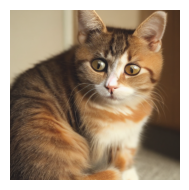

-----
Computing SVD basis at layer mid[0]...


OutOfMemoryError: CUDA out of memory. Tried to allocate 256.00 MiB. GPU 0 has a total capacity of 47.41 GiB of which 51.06 MiB is free. Process 1029816 has 47.34 GiB memory in use. Of the allocated memory 46.75 GiB is allocated by PyTorch, and 88.72 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [9]:
# prompts=["water", "a horse in a field of flowers", "a small house on a mountain top"]
prompts = ["cat"]
alpha_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]  # your alphas
select_list = [0, 1, 2, 3, 4, 5]  # sv = 0..3, like your loop
generator = torch.Generator(device="cuda").manual_seed(SEED)
start_latents = torch.randn(1, 4, 64, 64, device="cuda", generator=generator)
start_latents *= scheduler.init_noise_sigma


for prompt in prompts:
    
    print("--------------------------------------------------")
    print ("Prompt: ", prompt)
    print("--------------------------------------------------")
    
    # call it once
    prompt_embedding = get_text_embeddings(
        prompt=prompt,
        batch_size=1,  # type: ignore
        tokenizer=tokenizer,
        text_encoder=text_encoder,
        with_grad=False,
    )

    image = generate_images_from_latents(
        start_latents,
        prompt_embedding,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    ).squeeze()
    
    print("-----")
    print("Original Image:")
    show_image(image)
    print("-----")
    
    for hook_proportion in [0.6]:

        x_T_stars = svd_mutation_many(
            start_latents,
            prompt_embedding,
            unet,
            scheduler,
            guidance_scale=guidance_scale,
            num_inference_steps=num_inference_steps,
            hook_proportion=hook_proportion,
            alpha_list=alpha_list,
            select_list=select_list,
            
        )
        
        # 5) Render each edited restart image (preserve your print format)
        combos = list(itertools.product([hook_proportion], select_list, alpha_list))
        for (hook_p, sv, alpha), x_T_star in zip(combos, x_T_stars):
            print(f"Hooking at {hook_p} SV {sv} Alpha {alpha}")
            img_restart = generate_images_from_latents(
                x_T_star,
                prompt_embedding,
                num_inference_steps=num_inference_steps,
                guidance_scale=guidance_scale,
                scheduler=scheduler,
                unet=unet,
                vae=vae,
            ).squeeze()
            show_image(img_restart)

In [ ]:
# for sigma in [0.001, 0.005, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0, 5.0]:
#     for i in range(1):
#         print("Adding noise to xt with sigma =", sigma, "experiment", i)
#         new_latents = start_latents + torch.randn_like(start_latents) * sigma
#         new_img = generate_images_from_latents(
#             new_latents,
#             prompt_embedding,
#             num_inference_steps,
#             guidance_scale,
#             scheduler,
#             unet,
#             vae
#         ).squeeze()
#         show_image(new_img)

# for sigma in [0.001, 0.005, 0.01, 0.005, 0.1, 0.25, 0.5, 0.75, 1.0, 5.0]:
#     for i in range(1):
#         print("Adding noise to prompt embed with sigma =", sigma, "experiment", i)
#         new_prompt_embedding = prompt_embedding + torch.randn_like(prompt_embedding) * sigma
#         new_img = generate_images_from_latents(
#             start_latents,
#             new_prompt_embedding,
#             num_inference_steps,
#             guidance_scale,
#             scheduler,
#             unet,
#             vae
#         ).squeeze()
#         show_image(new_img)

In [ ]:
## TEST INVERSION


# print("--------------------------------")
# print("Start latents:", start_latents)
# print("--------------------------------")

# latents, _, _, timesteps = roll_to_hook(
#     start_latents,
#     prompt_embedding, 
#     unet=unet,
#     scheduler=scheduler, 
#     guidance_scale=3.5,
#     num_steps=50,
#     hook_idx=50,
#     device="cuda"
# )

# print("--------------------------------")
# print("Latents:", latents)
# print("--------------------------------")

# x_T_star = invert_to_start(
#     latents,
#     prompt_embedding,
#     unet=unet,
#     scheduler=scheduler,
#     guidance_scale=guidance_scale,
#     timesteps=timesteps,
#     hook_idx=50,
#     device="cuda"
# )

# img = generate_images_from_latents(
#     x_T_star,
#     prompt_embedding,
#     50,
#     guidance_scale,
#     scheduler,
#     unet,
#     vae
# )

# show_image(img[0])